In [3]:
import pandas as pd
import numpy as np 
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, roc_auc_score, roc_curve


# LOAD DATA
df = pd.read_csv("C:/Users/tsson/Downloads/drive-download-20251102T105633Z-1-001/Assignment 3/Admission_Predict.csv")

df

print(df.head())

print(df.info())

# CLEAN COLUMN NAMES

df.columns = df.columns.str.strip()

# CREATE BINARY TARGET (Admit = 1 if Chance of Admit >= 0.5)
df['Admit'] = (df['Chance of Admit'] >= 0.5).astype(int)

df['Admit']



   Serial No.  GRE Score  TOEFL Score  University Rating  SOP  LOR   CGPA  \
0           1        337          118                  4  4.5   4.5  9.65   
1           2        324          107                  4  4.0   4.5  8.87   
2           3        316          104                  3  3.0   3.5  8.00   
3           4        322          110                  3  3.5   2.5  8.67   
4           5        314          103                  2  2.0   3.0  8.21   

   Research  Chance of Admit   
0         1              0.92  
1         1              0.76  
2         1              0.72  
3         1              0.80  
4         0              0.65  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Serial No.         400 non-null    int64  
 1   GRE Score          400 non-null    int64  
 2   TOEFL Score        400 non-null    int64  
 

0      1
1      1
2      1
3      1
4      1
      ..
395    1
396    1
397    1
398    1
399    1
Name: Admit, Length: 400, dtype: int32

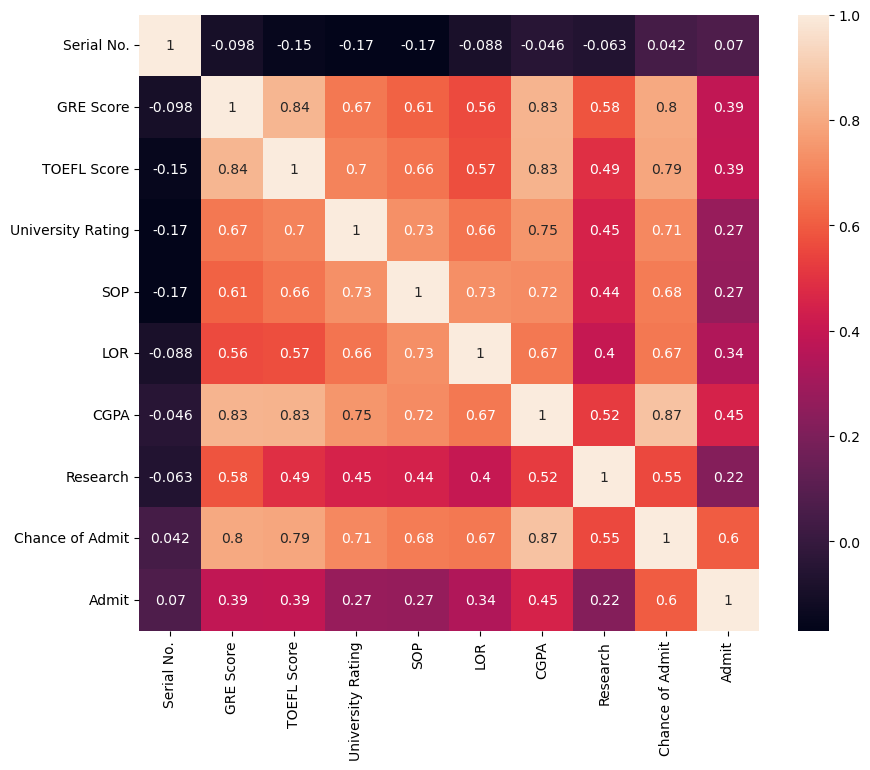

In [5]:
# ------------------------------
# CORRELATION & HEATMAP
# ------------------------------
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,8))
heatmap = sns.heatmap(df.corr(), annot=True)

correlation_admit = df.corr()['Admit'].sort_values(ascending=False)
correlation_admit

# ------------------------------
# FEATURES & TARGET
# ------------------------------
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
target = ['Admit']

X = df[features]
y = df[target]



In [8]:
import numpy as np
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y )
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)


Training data shape: (280, 7)
Testing data shape: (120, 7)


In [10]:
from sklearn.linear_model import LogisticRegression
log_reg = LogisticRegression(class_weight='balanced')
log_reg.fit(X_train, y_train)


y_pred = log_reg.predict(X_test)
y_pred_proba = log_reg.predict_proba(X_test)[:,1]
y_pred_proba


print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.7833333333333333

Classification Report:
               precision    recall  f1-score   support

           0       0.25      0.80      0.38        10
           1       0.98      0.78      0.87       110

    accuracy                           0.78       120
   macro avg       0.61      0.79      0.62       120
weighted avg       0.92      0.78      0.83       120



C:\Users\tsson\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1300: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\tsson\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [11]:
auc =roc_auc_score(y_test, y_pred)
print("roc auc score:", auc)


roc auc score: 0.790909090909091
